# Quartz / air / Si three-layer THz-TDS fit with **coarse-grid** $n(f)$, $k(f)$ (6 knots per curve, no polynomial)

Companion to `QuartzAirSi_dispersive_Adam.ipynb` (polynomial version) and three-layer counterpart of
`QuartzSI_grid_Adam.ipynb`. Each layer's $n(f)$ and $k(f)$ are described by their **values at 6 equally spaced knot
frequencies** inside the fit band; between the knots the curve is interpolated by a natural cubic spline (`INTERP`,
`'linear'` also available), outside the band it is held at the edge value:

$$
n_j(f) = \sum_{q=1}^{6} A_q(f)\, n_{j,q}, \qquad k_j(f) = \sum_{q=1}^{6} A_q(f)\, k_{j,q},
$$

$A_q(f)$ are fixed basis functions (matrix `A` `[n_freq, 6]`, built once by interpolating the unit vectors), the knot
values $n_{j,q}$, $k_{j,q}$ are the free parameters. No assumption about the *shape* of the dispersion is made.

Stack: **quartz (1 mm) / air gap / Si (0.4 mm)**, **run 3** data `ref_3.txt`, `quartz_air_silicon_15_min_3.txt` (21 Oct 2026;
the same stack re-measured — run 2 of 20 Oct is `QuartzAirSi_grid_Adam.ipynb`).

* **Quartz** and **Si**: 6 $n$ knots + 6 $k$ knots + $d$ each.
* **Air**: $n = 1$, $k = 0$ **fixed** (`fit_n = fit_k = False`); only $d_{air}$ is fitted (start 50 µm, step scale 200 µm).

Total 2 × 12 + 3 = 27 free parameters. Everything else is as in the polynomial notebook: exact transfer matrix applied to
the measured reference pulse, time-domain loss (MAE + log-cosh), Adam, two stages (**knots tied** = flat → **knots free**),
soft $k \ge 0$ hinge penalty, loss scans. Model code: `dispersive_multilayer_grid.py` (`Simulate.py` unchanged).

In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))

In [2]:
try:
    import ipympl  # noqa
    %matplotlib widget
except ImportError:
    %matplotlib inline

In [3]:
import copy, os
import numpy as np
import matplotlib.pyplot as plt
import torch

from dispersive_multilayer_grid import Grid, DispersiveMultiLayerGrid, interp_basis, fit, total_loss
from data_quartz_air_si import load_run
RUN = 'run3'
t_r, A_r, A_s = load_run(RUN)

torch.set_default_dtype(torch.float32)

## 1. Data

L = 3486, dt = 33.0 fs, window = 115.0 ps, df = 2.17 GHz


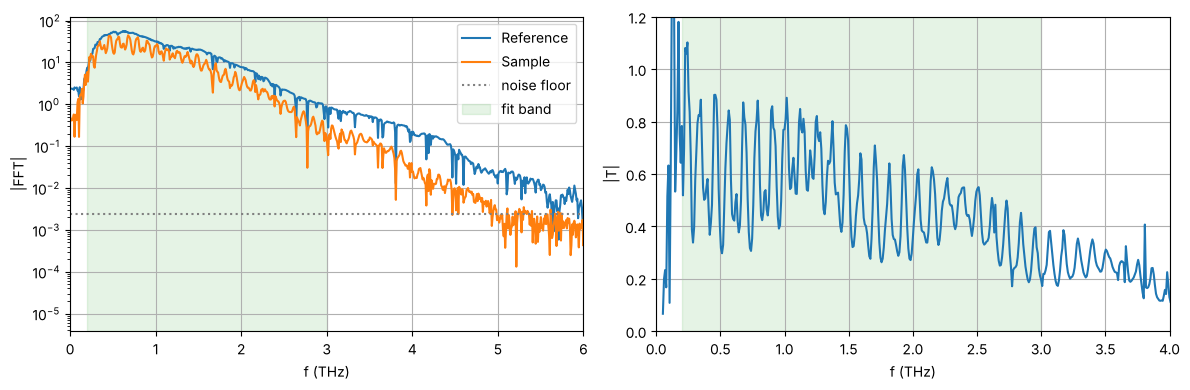

In [4]:
L = len(A_r)
deltat = (t_r[1] - t_r[0]) * 1e-12
t_r = t_r - t_r[0]

x_exp = np.asarray(A_r, dtype=np.float32)          # reference pulse
true_x_exp = np.asarray(A_s, dtype=np.float32)     # sample pulse

F_LO, F_HI = 0.2, 3.0            # THz : fit band = knot range
grid = Grid(L, deltat, f_lo=F_LO, f_hi=F_HI)
f_np = grid.f_np
print(f"L = {L}, dt = {deltat*1e15:.1f} fs, window = {t_r[-1]:.1f} ps, df = {grid.deltaf/1e9:.2f} GHz")

f_data = np.fft.rfftfreq(L, deltat) / 1e12
S_ref = np.abs(np.fft.rfft(x_exp)); S_sam = np.abs(np.fft.rfft(true_x_exp))
noise_floor = np.median(S_ref[f_data > 6.0])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(f_data, S_ref, label='Reference'); ax[0].semilogy(f_data, S_sam, label='Sample')
ax[0].axhline(noise_floor, color='gray', ls=':', label='noise floor'); ax[0].axvspan(F_LO, F_HI, color='C2', alpha=0.12, label='fit band')
ax[0].set_xlim(0, 6); ax[0].set_xlabel('f (THz)'); ax[0].set_ylabel('|FFT|'); ax[0].legend(); ax[0].grid()
ok = f_data > 0.05
ax[1].plot(f_data[ok], (S_sam / S_ref)[ok]); ax[1].axvspan(F_LO, F_HI, color='C2', alpha=0.12)
ax[1].set_xlim(0, 4); ax[1].set_ylim(0, 1.2); ax[1].set_xlabel('f (THz)'); ax[1].set_ylabel('|T|'); ax[1].grid()
plt.tight_layout(); plt.show()

## 2. Knot grid and interpolation basis

knot frequencies (THz): [0.2  0.76 1.32 1.88 2.44 3.  ]


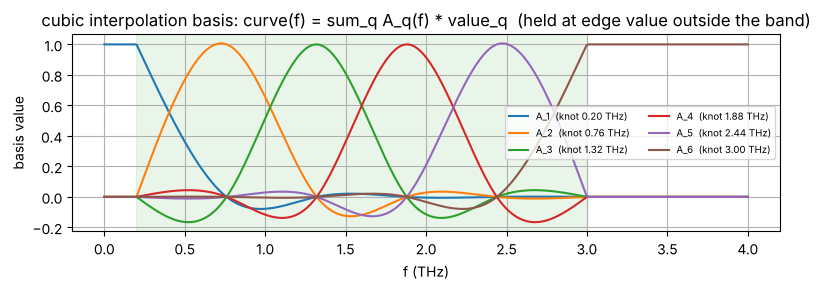

In [5]:
N_KNOTS = 6
INTERP  = 'cubic'        # 'cubic' (natural cubic spline through the knots) or 'linear'

f_knots = np.linspace(F_LO, F_HI, N_KNOTS)
print("knot frequencies (THz):", np.round(f_knots, 3))

f_show = np.linspace(0, 4, 400)
A_show = interp_basis(f_show, f_knots, INTERP)
plt.figure(figsize=(8, 3))
for q in range(N_KNOTS):
    plt.plot(f_show, A_show[:, q], label=f'A_{q+1}  (knot {f_knots[q]:.2f} THz)')
plt.axvspan(F_LO, F_HI, color='C2', alpha=0.10); plt.xlabel('f (THz)'); plt.ylabel('basis value'); plt.legend(fontsize=7, ncol=2); plt.grid()
plt.title(f'{INTERP} interpolation basis: curve(f) = sum_q A_q(f) * value_q  (held at edge value outside the band)')
plt.tight_layout(); plt.show()

## 3. Three-layer model

Same layer specs as the polynomial notebook. The knot step scale `n_scale` is **0.1** (absolute index units; the two-layer
grid notebook used 0.05): Adam moves each knot by ≈ `lr × n_scale` = 1e-5 per iteration, so Si can travel from the 3.40
start to ~3.35 well within stage 1.

In [6]:
layer_specs = [
    dict(name='quartz', n=1.9820, k=0.0071, d=1.0e-3),
    dict(name='air',    n=1.0,    k=0.0,    d=50e-6,  fit_n=False, fit_k=False, d_scale=200e-6),   # n = 1 fixed
    dict(name='Si',     n=3.4000, k=0.0054, d=0.4e-3),
]

FIT_THICKNESS = True
N_ITERS_FLAT = 15000
N_ITERS_DISP = 30000
LR = 1e-4
K_POS_WEIGHT = 1.0
N_SCALE, K_SCALE = 0.1, 0.005

## 4. Plot helpers

In [7]:
def mae_loss(y_test, y_pred):
    return np.mean(np.abs(y_test - y_pred))

def plot_loss(trajs, labels):
    plt.figure(figsize=(10, 3.5)); off = 0
    for traj, lab in zip(trajs, labels):
        plt.plot(np.arange(off, off + len(traj['loss'])), traj['loss'], label=lab); off += len(traj['loss'])
    off = 0
    for traj, lab in zip(trajs, labels):
        if np.any(traj['penalty'] > 0):
            plt.plot(np.arange(off, off + len(traj['penalty'])), traj['penalty'], ls=':', label=f'{lab}: k-penalty part')
        off += len(traj['loss'])
    plt.yscale('log'); plt.xlabel('Iteration'); plt.ylabel('Loss'); plt.legend(); plt.grid(); plt.title('Optimization'); plt.show()


def plot_pulses(model, title=''):
    with torch.no_grad():
        _, y = model.forward(x_exp)
    y = y.numpy()
    print(f"MAE = {mae_loss(true_x_exp, y):.4e}")
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    ax[0].plot(t_r, true_x_exp, label='Sample Pulse (Experimental)', color='C1')
    ax[0].plot(t_r, y, label='Sample Pulse (Simulated, 6-knot n(f), k(f))', color='black', alpha=0.75, ls='--')
    ax[0].set_title(title); ax[0].legend(); ax[0].grid()
    ax[1].plot(t_r, true_x_exp - y, color='C3', lw=0.8); ax[1].set_ylabel('residual'); ax[1].set_xlabel('t (ps)'); ax[1].grid()
    plt.tight_layout(); plt.show()


def _poly_curves(npz, f, j):
    P = np.load(npz)
    xp = (np.clip(f, float(P['F_LO']), float(P['F_HI'])) - float(P['F_REF'])) / float(P['F_SCALE'])
    return np.polyval(P['n_coefs'][j][::-1], xp), np.polyval(P['k_coefs'][j][::-1], xp)


def plot_nk(models, labels, f_plot=np.linspace(0.05, 4.0, 400), which=(0, 2),
            poly_npz=f'QuartzAirSi_{RUN}_poly_coefs.npz', prev_grid_npz='QuartzAirSi_grid_knots.npz'):
    '''n(f), k(f) of the fitted layers with the knots marked; overlays: the polynomial 3-layer fit (dashed grey), the
    run-2 6-knot fit of the same stack (dotted), the HRFZ-Si literature index.'''
    fig, ax = plt.subplots(2, len(which), figsize=(6 * len(which), 7))
    for m, lab in zip(models, labels):
        with torch.no_grad():
            n, k = m.nk(f_plot); st = m.state()
        for col, j in enumerate(which):
            ln, = ax[0, col].plot(f_plot, n[j].numpy(), label=lab); ax[0, col].plot(m.f_knots, st['n'][j].numpy(), 'o', color=ln.get_color(), ms=4)
            lk, = ax[1, col].plot(f_plot, k[j].numpy(), label=lab); ax[1, col].plot(m.f_knots, st['k'][j].numpy(), 'o', color=lk.get_color(), ms=4)
    if poly_npz and os.path.exists(poly_npz):
        for col, j in enumerate(which):
            n_p, k_p = _poly_curves(poly_npz, f_plot, j)
            ax[0, col].plot(f_plot, n_p, '--', color='gray', label=f'polynomial fit, {RUN} (if already run)')
            ax[1, col].plot(f_plot, k_p, '--', color='gray', label=f'polynomial fit, {RUN} (if already run)')
    if prev_grid_npz and os.path.exists(prev_grid_npz):
        G = np.load(prev_grid_npz); Ag = interp_basis(f_plot, G['f_knots'], str(G['interp']))
        for col, (j, jg) in enumerate(zip(which, (0, 2))):
            ax[0, col].plot(f_plot, Ag @ G['n_knots'][jg], ':', color='C3', label='run 2 (20 Oct), 6-knot')
            ax[1, col].plot(f_plot, Ag @ G['k_knots'][jg], ':', color='C3', label='run 2 (20 Oct), 6-knot')
    for col, j in enumerate(which):
        if models[0].names[j] == 'Si':
            ax[0, col].axhline(3.4175, color='C1', ls='-.', lw=1, label='HRFZ Si, Dai et al. 2004 (3.4175)')
        for i, q in enumerate(['n', 'k']):
            a = ax[i, col]; a.axvspan(F_LO, F_HI, color='C2', alpha=0.10)
            a.set_xlabel('f (THz)'); a.set_ylabel(f'{q}(f)'); a.grid(); a.legend(fontsize=8)
            if q == 'k': a.axhline(0, color='k', lw=0.6)
        ax[0, col].set_title(f'layer {j+1} ({models[0].names[j]})')
    plt.tight_layout(); plt.show()


def plot_spectral_residual(models, labels):
    plt.figure(figsize=(10, 3.5))
    plt.semilogy(f_data, S_sam, color='gray', alpha=0.5, label='|sample spectrum|')
    for m, lab in zip(models, labels):
        with torch.no_grad():
            _, y = m.forward(x_exp)
        plt.semilogy(f_data, np.abs(np.fft.rfft(true_x_exp - y.numpy())), label=f'|residual| {lab}')
    plt.axvspan(F_LO, F_HI, color='C2', alpha=0.10); plt.xlim(0, 5); plt.xlabel('f (THz)'); plt.legend(); plt.grid(); plt.show()


def plot_knot_history(traj, model, title='', which=(0, 2)):
    fig, ax = plt.subplots(2, len(which), figsize=(6 * len(which), 6))
    for col, j in enumerate(which):
        for q in range(model.N_KNOTS):
            ax[0, col].plot(traj['n'][:, j, q] - traj['n'][0, j, q], label=f'n knot {model.f_knots[q]:.2f} THz')
            ax[1, col].plot(traj['k'][:, j, q] - traj['k'][0, j, q], label=f'k knot {model.f_knots[q]:.2f} THz')
        ax[0, col].set_title(f'{model.names[j]} {title}'); ax[0, col].legend(fontsize=7); ax[0, col].grid(); ax[0, col].set_ylabel('n - n(0)')
        ax[1, col].legend(fontsize=7); ax[1, col].grid(); ax[1, col].set_xlabel('iteration'); ax[1, col].set_ylabel('k - k(0)')
    plt.tight_layout(); plt.show()


def plot_thickness_history(trajs, labels, names):
    fig, ax = plt.subplots(1, len(names), figsize=(5 * len(names), 3.5)); off = 0
    for traj, lab in zip(trajs, labels):
        it = np.arange(off, off + len(traj['d']))
        for j, nm in enumerate(names):
            ax[j].plot(it, traj['d'][:, j] * 1e6, label=lab)
        off += len(traj['d'])
    for j, nm in enumerate(names):
        ax[j].set_title(f'd_{nm}'); ax[j].set_ylabel('um'); ax[j].set_xlabel('iteration'); ax[j].grid(); ax[j].legend()
    plt.tight_layout(); plt.show()

## 5. Stage 1 — knots tied (flat $n$, $k$; $d$ free; air $n = 1$)

[flat] Epoch=     1  loss=3.8664e-02 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.98200 k=0.00710 d=1000.0um | air: n=1.00000 k=0.00000 d=50.0um | Si: n=3.40000 k=0.00540 d=400.0um |


fit flat:   0%|          | 0/14999 [00:00<?, ?it/s]

[flat] Epoch=  2500  loss=8.8688e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.96966 k=0.00680 d=980.4um | air: n=1.00000 k=0.00000 d=101.4um | Si: n=3.39280 k=0.00492 d=389.2um |


[flat] Epoch=  5000  loss=3.9731e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97311 k=0.00516 d=975.7um | air: n=1.00000 k=0.00000 d=126.9um | Si: n=3.39456 k=0.00324 d=388.7um |


[flat] Epoch=  7500  loss=3.7168e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97473 k=0.00435 d=974.7um | air: n=1.00000 k=0.00000 d=126.8um | Si: n=3.39591 k=0.00214 d=388.5um |


[flat] Epoch= 10000  loss=3.6482e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97378 k=0.00451 d=975.2um | air: n=1.00000 k=0.00000 d=126.8um | Si: n=3.39629 k=0.00127 d=388.5um |


[flat] Epoch= 12500  loss=3.6287e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97450 k=0.00485 d=974.9um | air: n=1.00000 k=0.00000 d=126.8um | Si: n=3.39421 k=0.00063 d=388.7um |


[flat] Epoch= 15000  loss=3.6223e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97537 k=0.00504 d=974.5um | air: n=1.00000 k=0.00000 d=126.8um | Si: n=3.39030 k=0.00024 d=389.1um |
knots (THz): 0.200, 0.760, 1.320, 1.880, 2.440, 3.000
  quartz:  n knots = [1.97537, 1.97537, 1.97537, 1.97537, 1.97537, 1.97537]
           k knots = [+0.00504, +0.00504, +0.00504, +0.00504, +0.00504, +0.00504]      d =   974.48 um   k<0 in band: 0.0 %
     air:  n knots = [1.00000, 1.00000, 1.00000, 1.00000, 1.00000, 1.00000]   (n, k fixed)
           k knots = [+0.00000, +0.00000, +0.00000, +0.00000, +0.00000, +0.00000]      d =   126.78 um   k<0 in band: 0.0 %
      Si:  n knots = [3.39030, 3.39030, 3.39030, 3.39030, 3.39030, 3.39030]
           k knots = [+0.00024, +0.00024, +0.00024, +0.00024, +0.00024, +0.00024]      d =   389.13 um   k<0 in band: 0.0 %
MAE = 3.5903e-03


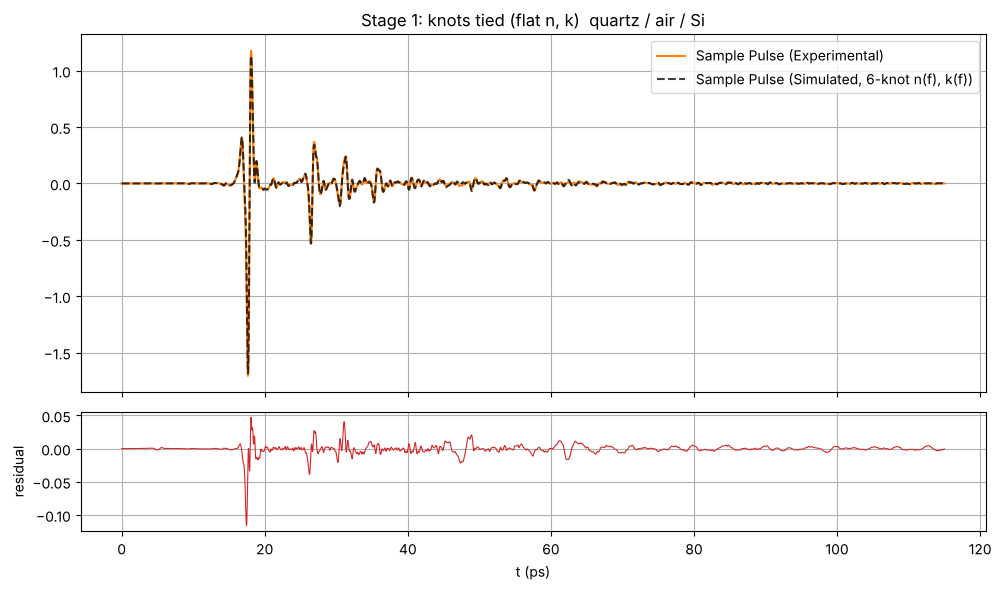

In [8]:
model = DispersiveMultiLayerGrid(grid, layer_specs, n_knots=N_KNOTS, interp=INTERP, n_scale=N_SCALE, k_scale=K_SCALE)
model.set_dispersion(False)
model.set_thickness(FIT_THICKNESS)

traj_flat = fit(model, x_exp, true_x_exp, n_iters=N_ITERS_FLAT, lr=LR, print_step=2500, label='flat', k_pos_weight=K_POS_WEIGHT)
model.report()
plot_pulses(model, title='Stage 1: knots tied (flat n, k)  quartz / air / Si')

## 6. Stage 2 — every knot free

In [9]:
model_flat = copy.deepcopy(model)

model.load_state(model.state())
model.set_dispersion(True)
model.set_thickness(FIT_THICKNESS)

traj_disp = fit(model, x_exp, true_x_exp, n_iters=N_ITERS_DISP, lr=LR, print_step=5000, label='6-knot', k_pos_weight=K_POS_WEIGHT)
model.report()

[6-knot] Epoch=     1  loss=3.6223e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97537 k=0.00504 d=974.5um | air: n=1.00000 k=0.00000 d=126.8um | Si: n=3.39030 k=0.00024 d=389.1um |


fit 6-knot:   0%|          | 0/29999 [00:00<?, ?it/s]

[6-knot] Epoch=  5000  loss=2.9785e-03 (k-pen 3.5e-07)  [knot 0.76 THz] quartz: n=1.97293 k=0.00328 d=975.7um | air: n=1.00000 k=0.00000 d=125.5um | Si: n=3.38884 k=0.00011 d=389.3um |


[6-knot] Epoch= 10000  loss=2.9392e-03 (k-pen 2.0e-07)  [knot 0.76 THz] quartz: n=1.97246 k=0.00341 d=975.9um | air: n=1.00000 k=0.00000 d=125.7um | Si: n=3.38906 k=0.00001 d=389.3um |


[6-knot] Epoch= 15000  loss=2.9334e-03 (k-pen 2.9e-07)  [knot 0.76 THz] quartz: n=1.97193 k=0.00345 d=976.2um | air: n=1.00000 k=0.00000 d=125.9um | Si: n=3.38963 k=-0.00002 d=389.3um |


[6-knot] Epoch= 20000  loss=2.9329e-03 (k-pen 2.5e-07)  [knot 0.76 THz] quartz: n=1.97164 k=0.00345 d=976.4um | air: n=1.00000 k=0.00000 d=125.9um | Si: n=3.39059 k=-0.00002 d=389.1um |


[6-knot] Epoch= 25000  loss=2.9328e-03 (k-pen 2.7e-07)  [knot 0.76 THz] quartz: n=1.97141 k=0.00344 d=976.5um | air: n=1.00000 k=0.00000 d=125.9um | Si: n=3.39158 k=-0.00002 d=389.0um |


[6-knot] Epoch= 30000  loss=2.9327e-03 (k-pen 2.1e-07)  [knot 0.76 THz] quartz: n=1.97118 k=0.00343 d=976.6um | air: n=1.00000 k=0.00000 d=125.9um | Si: n=3.39256 k=-0.00001 d=388.9um |


knots (THz): 0.200, 0.760, 1.320, 1.880, 2.440, 3.000
  quartz:  n knots = [1.96516, 1.97118, 1.97265, 1.97454, 1.97805, 1.99174]
           k knots = [+0.00061, +0.00343, +0.00676, +0.00890, +0.01097, +0.01137]      d =   976.63 um   k<0 in band: 0.0 %
     air:  n knots = [1.00000, 1.00000, 1.00000, 1.00000, 1.00000, 1.00000]   (n, k fixed)
           k knots = [+0.00000, +0.00000, +0.00000, +0.00000, +0.00000, +0.00000]      d =   125.87 um   k<0 in band: 0.0 %
      Si:  n knots = [3.39625, 3.39256, 3.39277, 3.39397, 3.39163, 3.38171]
           k knots = [+0.00117, -0.00001, +0.00087, +0.00019, +0.00067, +0.00485]      d =   388.91 um   k<0 in band: 4.6 %


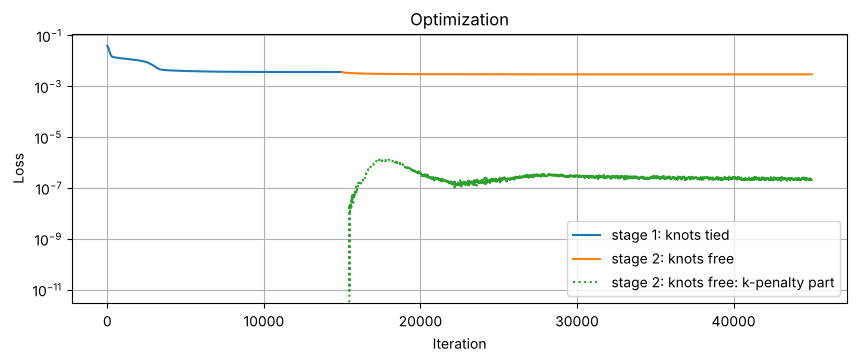

MAE = 2.9158e-03


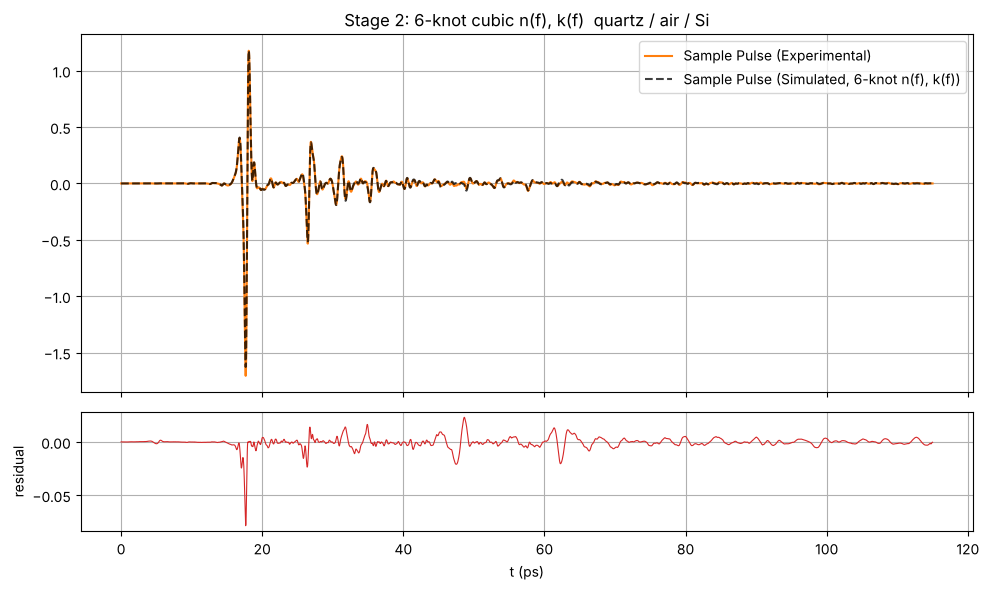

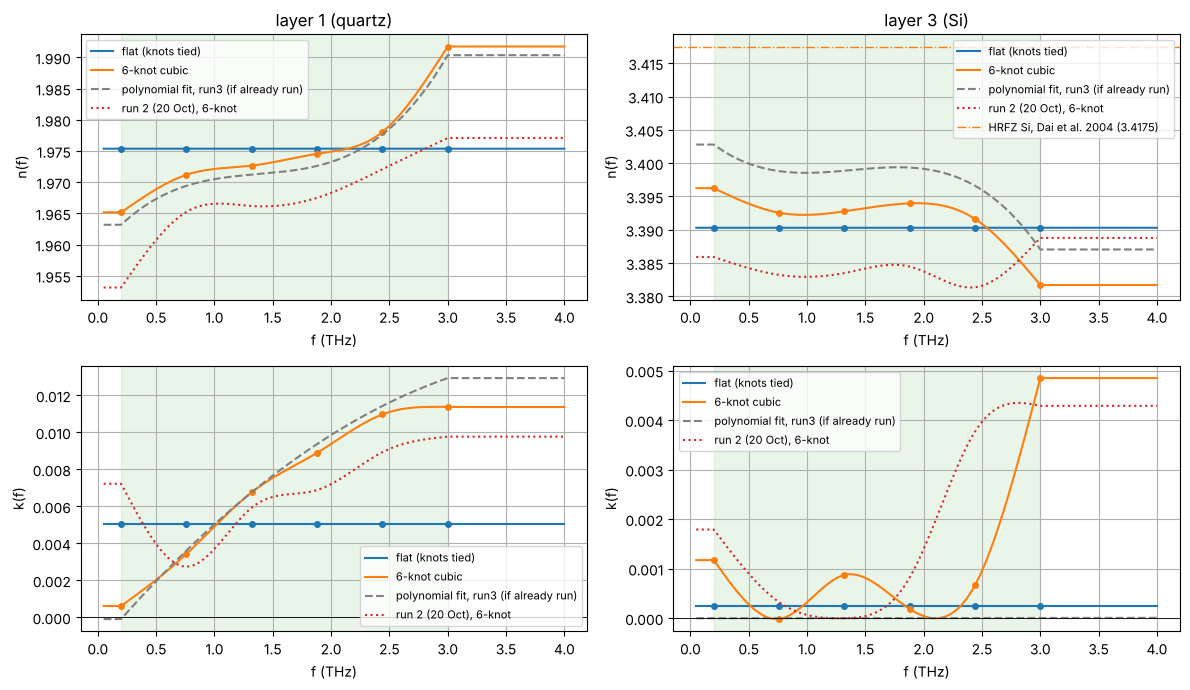

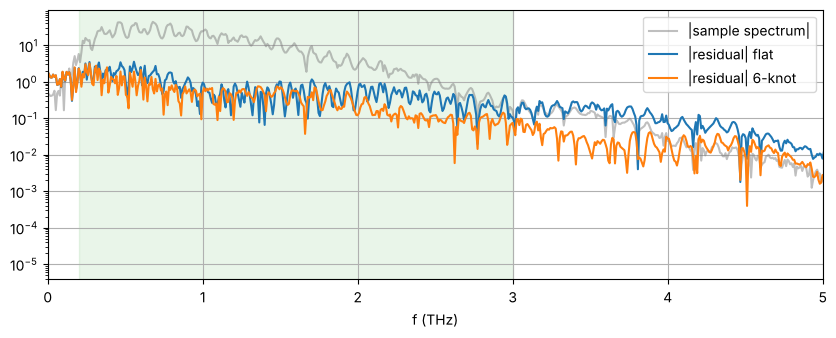

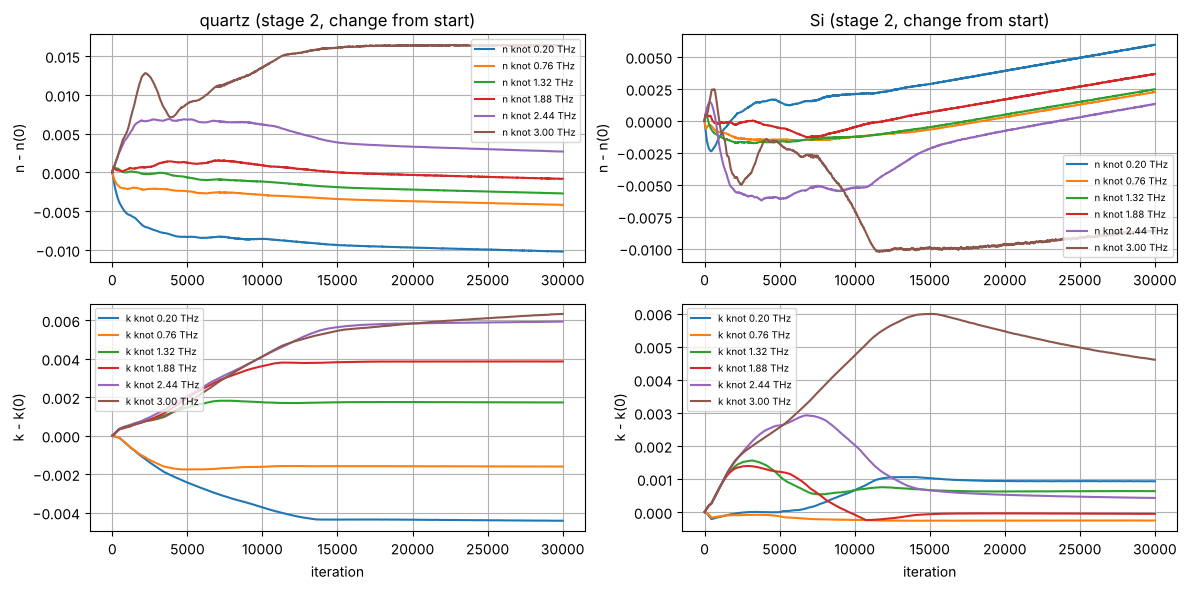

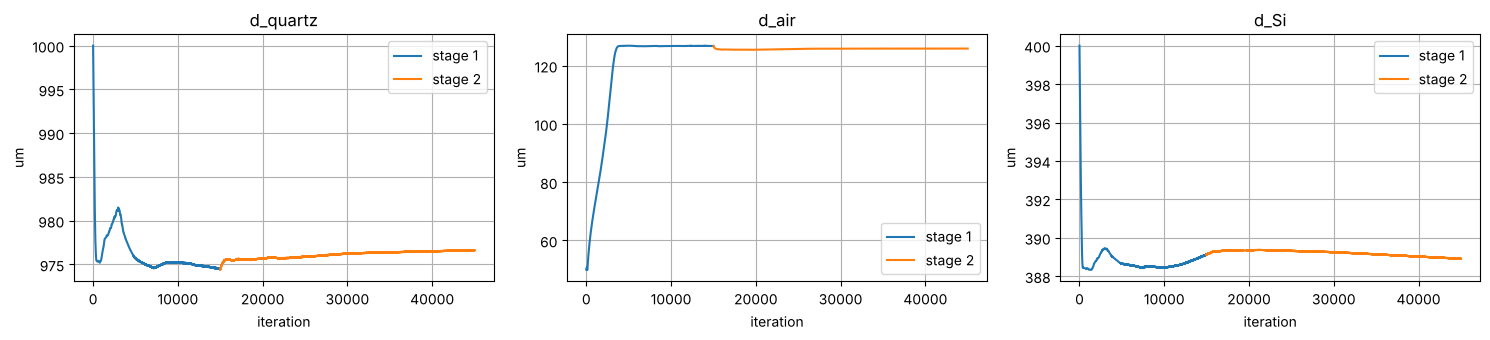

In [10]:
plot_loss([traj_flat, traj_disp], ['stage 1: knots tied', 'stage 2: knots free'])
plot_pulses(model, title=f'Stage 2: {N_KNOTS}-knot {INTERP} n(f), k(f)  quartz / air / Si')
plot_nk([model_flat, model], ['flat (knots tied)', f'{N_KNOTS}-knot {INTERP}'])
plot_spectral_residual([model_flat, model], ['flat', f'{N_KNOTS}-knot'])
plot_knot_history(traj_disp, model, '(stage 2, change from start)')
plot_thickness_history([traj_flat, traj_disp], ['stage 1', 'stage 2'], model.names)

## 7. Knot table and comparison with the polynomial fit of the same data

In [11]:
st = model.state()
nq, kq, ns, ks = st['n'][0].numpy(), st['k'][0].numpy(), st['n'][2].numpy(), st['k'][2].numpy()
print(f"{'f (THz)':>8} | {'n_quartz':>9} {'k_quartz':>9} | {'n_Si':>8} {'k_Si':>10} | {'n_Si-3.4175':>11}")
for q in range(N_KNOTS):
    print(f"{f_knots[q]:8.3f} | {nq[q]:9.4f} {kq[q]:9.5f} | {ns[q]:8.4f} {ks[q]:10.6f} | {ns[q]-3.4175:+11.4f}")
dq, da, ds = (st['d'][j].item() for j in range(3))
print(f"\nthicknesses: quartz {dq*1e6:.2f} um, air gap {da*1e6:.2f} um, Si {ds*1e6:.2f} um")

with torch.no_grad():
    n1, _ = model.nk(np.array([1.0]))
nq1, ns1 = n1[0, 0].item(), n1[2, 0].item()
print(f"n(1 THz): quartz {nq1:.4f}, Si {ns1:.4f}")
print(f"optical path n*d at 1 THz: quartz {nq1*dq*1e6:.1f} um, Si {ns1*ds*1e6:.1f} um  (-> d_Si = {ns1*ds*1e6/3.4175:.1f} um if n_Si = 3.4175)")

if os.path.exists('QuartzAirSi_grid_knots.npz'):
    G = np.load('QuartzAirSi_grid_knots.npz'); Ag1 = interp_basis(np.array([1.0]), G['f_knots'], str(G['interp']))
    gq1, gs1 = float((Ag1 @ G['n_knots'][0])[0]), float((Ag1 @ G['n_knots'][2])[0])
    print(f"\nrun 2 (20 Oct), 6-knot: quartz n(1THz) {gq1:.4f}, d {G['d'][0]*1e6:.1f} um (n*d {gq1*G['d'][0]*1e6:.1f}); "
          f"air {G['d'][1]*1e6:.1f} um; Si n {gs1:.4f}, d {G['d'][2]*1e6:.1f} um (n*d {gs1*G['d'][2]*1e6:.1f})")
    print("run 2 knots quartz n:", np.round(G['n_knots'][0], 4), " k:", np.round(G['k_knots'][0], 5))
    print("run 2 knots Si     n:", np.round(G['n_knots'][2], 4), " k:", np.round(G['k_knots'][2], 5))
print(f"final loss: {traj_disp['loss'][-1]:.4e}  (flat stage {traj_flat['loss'][-1]:.4e})")

 f (THz) |  n_quartz  k_quartz |     n_Si       k_Si | n_Si-3.4175
   0.200 |    1.9652   0.00061 |   3.3962   0.001173 |     -0.0213
   0.760 |    1.9712   0.00343 |   3.3926  -0.000014 |     -0.0249
   1.320 |    1.9727   0.00676 |   3.3928   0.000873 |     -0.0247
   1.880 |    1.9745   0.00890 |   3.3940   0.000187 |     -0.0235
   2.440 |    1.9781   0.01097 |   3.3916   0.000668 |     -0.0259
   3.000 |    1.9917   0.01137 |   3.3817   0.004847 |     -0.0358

thicknesses: quartz 976.63 um, air gap 125.87 um, Si 388.91 um
n(1 THz): quartz 1.9721, Si 3.3922
optical path n*d at 1 THz: quartz 1926.0 um, Si 1319.3 um  (-> d_Si = 386.0 um if n_Si = 3.4175)

run 2 (20 Oct), 6-knot: quartz n(1THz) 1.9665, d 980.2 um (n*d 1927.7); air 125.0 um; Si n 3.3829, d 389.9 um (n*d 1319.1)
run 2 knots quartz n: [1.9531 1.9652 1.9662 1.9675 1.9721 1.9771]  k: [0.00722 0.00274 0.00593 0.00688 0.00893 0.00977]
run 2 knots Si     n: [3.3859 3.3832 3.3835 3.3845 3.3814 3.3888]  k: [0.00179 0.00032 0.  

## 8. Loss scans: air gap and the $n$–$d$ valleys

(a) loss vs $d_{air}$; (b), (c) a common offset of all $n$ knots of a layer vs its thickness (±3 %), with the $n d$ = const
line and the run-2 6-knot solution marked.

d_air scan: minimum at 126.0 um; loss at 50 um = 1.622e-02 vs 2.937e-03


quartz: loss along the valley (min over d) at mean n = 1.916: 1.615e-02, 1.940: 7.220e-03, 1.964: 3.786e-03, 1.987: 4.011e-03, 2.011: 7.284e-03, 2.035: 1.416e-02


Si: loss along the valley (min over d) at mean n = 3.290: 7.747e-03, 3.330: 4.197e-03, 3.371: 3.263e-03, 3.412: 3.375e-03, 3.453: 4.167e-03, 3.493: 6.138e-03


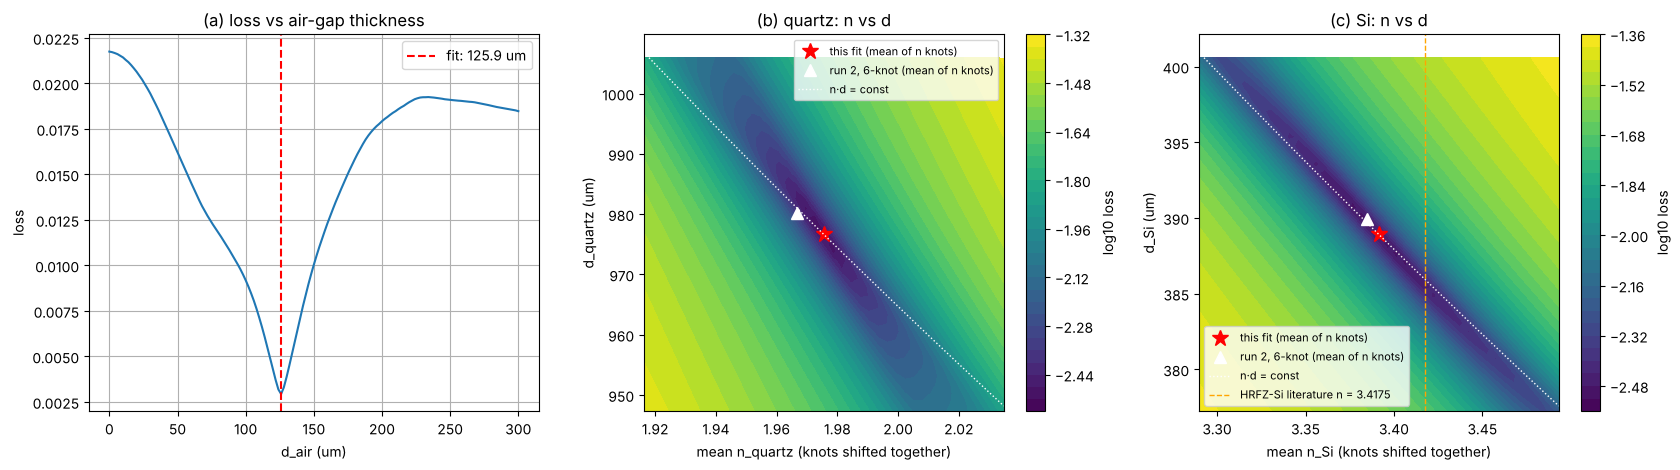

In [12]:
def loss_at(m):
    with torch.no_grad():
        _, y = m.forward(x_exp)
        return total_loss(y, torch.as_tensor(true_x_exp), m, K_POS_WEIGHT).item()

ms = copy.deepcopy(model); ms.load_state(ms.state())
d0 = st['d'].numpy().copy(); n0 = st['n'].numpy().copy()

d_scan = np.linspace(0, 300e-6, 151); loss_air = []
for v in d_scan:
    ms.d_init[1] = float(v); loss_air.append(loss_at(ms))
ms.d_init[1] = float(d0[1]); loss_air = np.array(loss_air)
print(f"d_air scan: minimum at {d_scan[loss_air.argmin()]*1e6:.1f} um; loss at 50 um = {loss_air[np.argmin(abs(d_scan-50e-6))]:.3e} vs {loss_air.min():.3e}")

def landscape(m, j, span=0.03, npts=41):
    nbar = n0[j].mean()
    offs = nbar * np.linspace(-span, span, npts); dd = d0[j] * (1 + np.linspace(-span, span, npts))
    Z = np.zeros((npts, npts))
    for a, o in enumerate(offs):
        m.n_init[j] = torch.tensor(n0[j] + o)
        for b, dv in enumerate(dd):
            m.d_init[j] = float(dv); Z[b, a] = loss_at(m)
    m.n_init[j] = torch.tensor(n0[j]); m.d_init[j] = float(d0[j])
    return nbar + offs, dd, Z

poly_pt = None
if os.path.exists('QuartzAirSi_grid_knots.npz'):
    G = np.load('QuartzAirSi_grid_knots.npz'); poly_pt = {j: (G['n_knots'][j].mean(), G['d'][j]) for j in (0, 2)}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(d_scan * 1e6, loss_air); ax[0].axvline(d0[1] * 1e6, color='r', ls='--', label=f'fit: {d0[1]*1e6:.1f} um')
ax[0].set_xlabel('d_air (um)'); ax[0].set_ylabel('loss'); ax[0].set_title('(a) loss vs air-gap thickness'); ax[0].grid(); ax[0].legend()
for col, (j, nm) in enumerate([(0, 'quartz'), (2, 'Si')], start=1):
    nn, dd, Z = landscape(ms, j)
    cf = ax[col].contourf(nn, dd * 1e6, np.log10(Z), 30, cmap='viridis'); plt.colorbar(cf, ax=ax[col], label='log10 loss')
    ax[col].plot(n0[j].mean(), d0[j] * 1e6, 'r*', ms=12, label='this fit (mean of n knots)')
    if poly_pt: ax[col].plot(poly_pt[j][0], poly_pt[j][1] * 1e6, 'w^', ms=9, label='run 2, 6-knot (mean of n knots)')
    ax[col].plot(nn, n0[j].mean() * d0[j] / nn * 1e6, 'w:', lw=1, label='n·d = const')
    if j == 2: ax[col].axvline(3.4175, color='orange', ls='--', lw=1, label='HRFZ-Si literature n = 3.4175')
    ax[col].set_xlabel(f'mean n_{nm} (knots shifted together)'); ax[col].set_ylabel(f'd_{nm} (um)'); ax[col].set_title(f'({"bc"[col-1]}) {nm}: n vs d'); ax[col].legend(fontsize=8)
    print(f"{nm}: loss along the valley (min over d) at mean n = " + ', '.join(f'{nn[i]:.3f}: {Z[:, i].min():.3e}' for i in range(0, 41, 8)))
plt.tight_layout(); plt.show()

## 9. Optional: Si thickness pinned to the literature index

Off by default (another 30 000 iterations). Pins $d_{Si} = n_{Si}(1\,\mathrm{THz})\, d_{Si} / 3.4175$ from the free fit and refits
from the stage-1 solution with every knot free.

In [13]:
RUN_PINNED_D_SI = False
N_SI_LIT = 3.4175

if RUN_PINNED_D_SI:
    D_SI_PINNED = ns1 * ds / N_SI_LIT
    print(f"pinning d_Si = {D_SI_PINNED*1e6:.2f} um")
    model_pin = copy.deepcopy(model_flat); model_pin.load_state(model_pin.state())
    model_pin.d_init[2] = D_SI_PINNED; model_pin.fit_d[2] = 0.0
    model_pin.set_dispersion(True)
    traj_pin = fit(model_pin, x_exp, true_x_exp, n_iters=N_ITERS_DISP, lr=LR, print_step=5000, label='d_Si pinned', k_pos_weight=K_POS_WEIGHT)
    model_pin.report()
    plot_pulses(model_pin, title=f'd_Si pinned at {D_SI_PINNED*1e6:.1f} um')
    plot_nk([model, model_pin], [f'{N_KNOTS}-knot, d free', f'{N_KNOTS}-knot, d_Si = {D_SI_PINNED*1e6:.1f} um'], poly_npz=None, prev_grid_npz=None)
    print(f"loss: d free {traj_disp['loss'][-1]:.4e}   d_Si pinned {traj_pin['loss'][-1]:.4e}")

## 10. Export

In [14]:
f_out = np.arange(F_LO, F_HI + 1e-9, 0.01)
with torch.no_grad():
    n_out, k_out = model.nk(f_out); n_out, k_out = n_out.numpy(), k_out.numpy()
table = np.column_stack([f_out, n_out[0], k_out[0], n_out[2], k_out[2]])
np.savetxt(f'QuartzAirSi_{RUN}_nk_of_f_grid.txt', table, fmt='%.6e',
           header=f'f_THz  n_quartz  k_quartz  n_Si  k_Si   (quartz/air/Si, {N_KNOTS}-knot {INTERP} interpolation, knots at '
                  + ', '.join(f'{f:.3f}' for f in f_knots) + f' THz; air n=1 fixed, d_air={da*1e6:.2f} um)')
np.savez(f'QuartzAirSi_{RUN}_grid_knots.npz', f_knots=f_knots, n_knots=st['n'].numpy(), k_knots=st['k'].numpy(), d=st['d'].numpy(),
         names=np.array(model.names), F_LO=F_LO, F_HI=F_HI, interp=INTERP)
print(table[::50])

[[ 2.00000000e-01  1.96516025e+00  6.12584408e-04  3.39624500e+00
   1.17317075e-03]
 [ 7.00000000e-01  1.97076130e+00  3.08646215e-03  3.39278078e+00
  -8.54360314e-06]
 [ 1.20000000e+00  1.97243953e+00  6.12435117e-03  3.39249420e+00
   7.31815002e-04]
 [ 1.70000000e+00  1.97392476e+00  8.25280417e-03  3.39371800e+00
   5.01674018e-04]
 [ 2.20000000e+00  1.97566628e+00  1.01892306e-02  3.39347768e+00
   4.74788176e-05]
 [ 2.70000000e+00  1.98340249e+00  1.13336388e-02  3.38770103e+00
   2.27702362e-03]]


## Notes

* `INTERP = 'linear'` gives piecewise-linear curves through the same knots (no overshoot between knots, but kinks).
* Knot count: `N_KNOTS`; the band edges are always knots. More knots = more freedom at the low-SNR band edges, where
  the $k$ knots are the least constrained (watch the k-penalty part of the loss and the `k<0 in band` report).
* Air gap: `fit_n = fit_k = False` keeps $n = 1$, $k = 0$ exactly; `fit_d = False` would also pin the gap.
* Degeneracy: only $n_j d_j$ is tightly fixed by the delays (section 8 b, c); the gap thickness is pinned sharply by the
  echo shape (section 8 a). Section 9 refits with $d_{Si}$ pinned to the literature index.